# GENIE BPC NSCLC v2.0-public — questions N1–N6

Source: Jacob's *CBIO thoughts* deck, slides 4–8. Data: AACR Project GENIE BPC NSCLC v2.0-public
(Synapse analytic, clinical, timeline and genomic files; see `data/genie/download_log_nsclc_brca.csv`).

**Conventions** (shared by every notebook, see `README.md`):

- Index date = **diagnosis** of the index NSCLC. OS in months, event = death (`os_dx_status`). Treatment questions use OS from the start of the regimen (`tt_os_g`).
- *X mut* = any non-synonymous somatic mutation in X on the patient's earliest sequenced sample of the index cancer. Amplification (+2), deep deletion (−2) and fusions are counted separately and labelled `amp`, `homdel`, `fus`.
- A patient is compared for a gene only if that gene is on the panel of the sample used; untested patients are dropped rather than called wild-type.
- Kaplan–Meier curves and log-rank p-values ignore the fact that patients enter GENIE only when sequenced (same as cBioPortal). The Cox hazard ratio reported next to each comparison is **left-truncated at the sequencing-report date** (labelled *HR (LT)*), which removes most of that immortal-time bias. Where the two disagree, trust the HR.
- Gene screens use ≥ 10 patients per group and Benjamini–Hochberg FDR (`q_bh`). Treat q < 0.1 as "worth a look", not as a result.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_nsclc"      # results/bpc_nsclc/
F = []                # one-line verdict per question, printed at the end

b = cb.BPC("NSCLC")
pd.Series(b.summary())

cohort                            NSCLC
patients                           1846
index_cancers                      1869
patients_with_2+_index_cancers       21
samples                            1988
samples_used                       1846
regimens                           3555
mutations_nonsyn                  16647
cna_profiled_samples               1778
sv_rows                             819
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log_nsclc_brca.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "NSCLC"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['2.0-public']


,category,filename,synapse_id,version,md5
0,docs,GENIE BPC NSCLC v2.0-public Analytic Data Guid...,syn30557304,5,1b345372d9b523f64e51bd2b54e090ec
1,docs,BPC_NSCLC_v2.0-public_variable_synopsis.xlsx,syn30557312,2,87962edb89e43eed4eb5f5446de2a229
2,docs,GENIE BPC cBioPortal Variable Crosswalk_NSCLC_...,syn29288708,2,451aeafe9f9b2dde94cdc1d7246a245a
3,analytic,patient_level_dataset.csv,syn30358096,2,4891d39a3dda8ddd37f12e7b55c6a389
4,analytic,cancer_level_dataset_index.csv,syn30358090,2,13e766aa4fc8f99d904fd201615c6063
5,analytic,cancer_level_dataset_non_index.csv,syn30358091,2,1584b2c68302bdf89b04ed5ddb5b46f0
6,analytic,cancer_panel_test_level_dataset.csv,syn30358092,2,e6e6eac427e6d1a02c86c2335e089f9f
7,analytic,regimen_cancer_level_dataset.csv,syn30358097,2,909d743fbefdb732ea1cff7621153bd3
8,analytic,imaging_level_dataset.csv,syn30358093,2,80e38b1301551afe51cd8cc80d66f121
9,analytic,med_onc_note_level_dataset.csv,syn30358094,2,5602d7b6bf0fa214e5412f2e8563ed05


## Cohort and alteration matrix

In [3]:
S = b.survival_dx()          # one row per patient: time (months from dx), event, entry (dx -> sequencing report), covariates
A = b.alterations()          # patient x gene matrices: A.mut / A.amp / A.homdel / A.fus (+ tested masks)

display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index NSCLC (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("With OS from diagnosis", int(S.time.notna().sum())),
]))
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel; "
      f"{int((S.entry >= S.time).sum())} patients have their sequencing report after the last follow-up date and are dropped from left-truncated models only.")
print(f"Deaths: {int(S.event.sum())} / {len(S)}.  Median OS from dx: {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months.")
display(pd.concat([S.stage_dx.value_counts().rename("stage_dx"), S.ca_hist_adeno_squamous.value_counts().rename("histology")], axis=1).fillna(""))

,step,n,dropped
0,Patients in release,1846,0
1,Index NSCLC (first index cancer per patient),1846,0
2,With a sequenced sample of the index cancer,1846,0
3,With OS from diagnosis,1846,0


21 patients had two index cancers (first used); 0 samples with unknown panel; 107 patients have their sequencing report after the last follow-up date and are dropped from left-truncated models only.
Deaths: 945 / 1846.  Median OS from dx: 45.7 months.


,stage_dx,histology
Stage IV,797,
Stage I,499,
Stage III,359,
Stage II,176,
Stage I-III NOS,12,
Adenocarcinoma,,1.15e+03
Carcinoma,,241
Squamous cell,,171
Other histologies/mixed tumor,,22
Small cell carcinoma,,5


,gene,kind,n_altered,n_tested,pct
0,TP53,mut,992,1846,53.7
1,KRAS,mut,569,1846,30.8
2,EGFR,mut,414,1846,22.4
3,STK11,mut,247,1687,14.6
4,KEAP1,mut,221,1627,13.6
5,KMT2D,mut,171,1632,10.5
6,ATM,mut,160,1687,9.5
7,SMARCA4,mut,142,1632,8.7
8,ARID1A,mut,137,1632,8.4
9,NF1,mut,135,1632,8.3


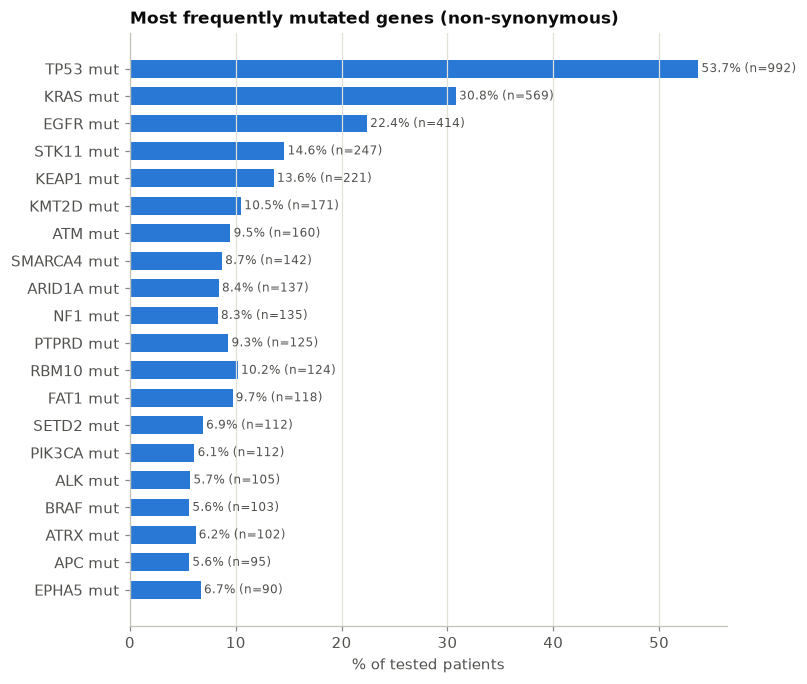

In [4]:
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes (non-synonymous)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
freq.head(15)

## N1 — What is the OS of patients with EGFR mutations?
EGFR-mutant vs EGFR-wild-type NSCLC, OS from diagnosis (slide 4).

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,EGFR wt,1432,755,42.3,0.808,0.66,0.375,9.9e-06,NaN,NaN,NaN,NaN
1,EGFR mut,414,190,56.5,0.942,0.814,0.463,9.9e-06,0.753,0.638,0.887,0.000714


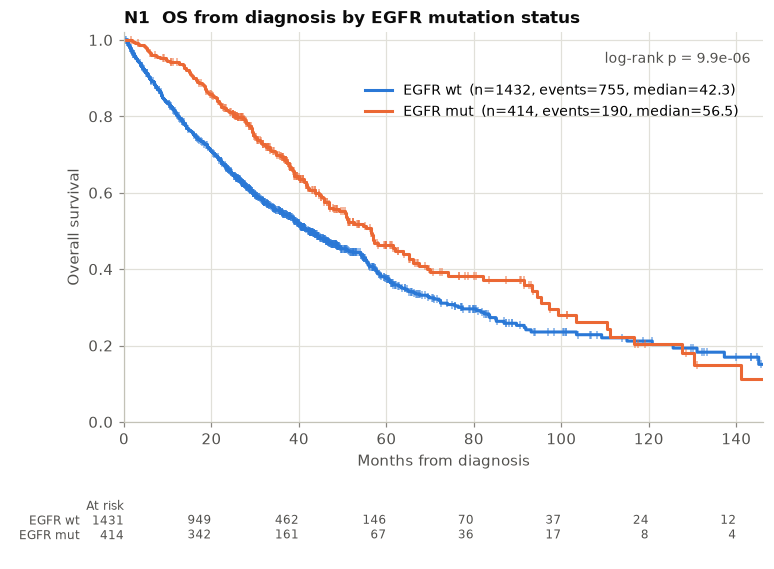

In [5]:
egfr = A.status("EGFR")                      # True = non-synonymous EGFR mutation (patients tested for EGFR)
egfr_ids = egfr.index[egfr]
d, tab = cb.compare(S, egfr, labels=("EGFR wt", "EGFR mut"), entry="entry")
ax, _ = cb.km_plot(d, "group", order=["EGFR wt", "EGFR mut"], title="N1  OS from diagnosis by EGFR mutation status", xlabel="Months from diagnosis")
cb.save(DS, "N1", table=tab, fig=ax.figure, slug="egfr_vs_wt")
display(tab)

Sensitivity: stage IV at diagnosis only (EGFR status is mostly actionable in advanced disease), and by EGFR mutation subtype.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,EGFR wt,584,429,20.3,0.638,0.441,0.165,4.95e-08,NaN,NaN,NaN,NaN
1,EGFR mut,213,139,38.3,0.901,0.701,0.263,4.95e-08,0.667,0.546,0.816,7.88e-05


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,classic (L858R / ex19del),310,130,63.8,0.961,0.834,0.527,0.00442
1,exon 20 insertion,22,11,40,0.955,0.854,0.21,0.00442
2,atypical / other,82,49,41.5,0.865,0.729,0.288,0.00442


[N1] confirmed: EGFR-mut (n=414) median OS 56.5 vs 42.3 mo in EGFR-wt; log-rank p=9.9e-06; HR (LT) 0.75 [0.64-0.89]. Stage IV only: HR 0.67. Classic sensitising mutations drive the benefit (median 63.8 mo).


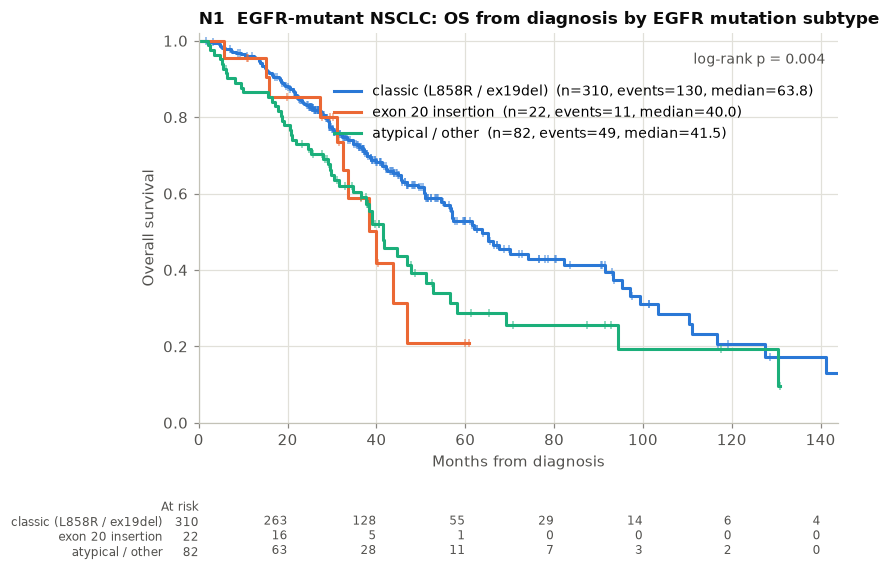

In [6]:
d4, tab4 = cb.compare(S[S.stage_dx == "Stage IV"], egfr, labels=("EGFR wt", "EGFR mut"), entry="entry")
display(tab4)

# EGFR subtype from the protein change of the sample used
def egfr_subtype(hgvsp):
    out = set()
    for h in hgvsp:
        h = str(h)
        pos = re.search(r"(\d+)", h)
        pos = int(pos.group(1)) if pos else -1
        if "L858R" in h: out.add("L858R")
        elif "T790M" in h: out.add("T790M")
        elif "del" in h and 729 <= pos <= 761: out.add("ex19del")
        elif ("ins" in h or "dup" in h) and 762 <= pos <= 823: out.add("ex20ins")
        else: out.add("other")
    if out & {"L858R", "ex19del"}: return "classic (L858R / ex19del)"
    if "ex20ins" in out: return "exon 20 insertion"
    return "atypical / other"

used = S.index.to_series().map(A.sample_of)
em = b.mut_long[(b.mut_long.gene == "EGFR") & b.mut_long.sample_id.isin(used)]
sub = em.groupby("sample_id").HGVSp_Short.apply(egfr_subtype)
S["egfr_subtype"] = used.map(sub)
ds = S.loc[egfr_ids].dropna(subset=["egfr_subtype"])
ax, tabs = cb.km_plot(ds, "egfr_subtype", title="N1  EGFR-mutant NSCLC: OS from diagnosis by EGFR mutation subtype", xlabel="Months from diagnosis",
                      order=["classic (L858R / ex19del)", "exon 20 insertion", "atypical / other"])
cb.save(DS, "N1", table=tabs, fig=ax.figure, slug="egfr_subtypes")
display(tabs)
cb.finding("N1", "confirmed",
           f"EGFR-mut (n={tab.n[1]}) median OS {tab.median_months[1]} vs {tab.median_months[0]} mo in EGFR-wt; log-rank p={cb.fmt_p(tab.p_logrank[0])}; "
           f"HR (LT) {tab.attrs['HR']:.2f} [{tab.attrs['HR_lo']:.2f}-{tab.attrs['HR_hi']:.2f}]. Stage IV only: HR {tab4.attrs['HR']:.2f}. "
           f"Classic sensitising mutations drive the benefit (median {tabs.set_index('group').median_months.get('classic (L858R / ex19del)')} mo).", F)

## N2 — How is OS in EGFR+ patients affected by co-occurring mutations?
Within EGFR-mutant patients, every co-alteration (mutation, amplification, deep deletion) with ≥ 10 carriers and ≥ 10 non-carriers is tested: log-rank, left-truncated Cox HR, BH FDR.

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,TP53 mut,TP53,mut,243,171,130,60,44.9,91.4,0.000114,1.77,1.29,2.43,0.000398,399,0.00743
1,NFKBIA amp,NFKBIA,amp,19,368,12,156,31.2,56.9,0.00491,2.12,1.15,3.92,0.0167,372,0.16
2,NKX2-1 amp,NKX2-1,amp,36,351,20,148,54.5,56.7,0.0256,1.71,1.06,2.77,0.0294,372,0.327
3,NOTCH2 mut,NOTCH2,mut,13,374,9,159,39.8,56.9,0.0299,2.32,1.13,4.76,0.0214,372,0.327
4,CDKN2A homdel,CDKN2A,homdel,42,345,27,141,34.7,56.9,0.0302,1.87,1.22,2.87,0.00437,372,0.327
5,TET2 mut,TET2,mut,13,374,9,159,30.2,56.7,0.0375,2.34,1.19,4.62,0.0143,372,0.348
6,MET amp,MET,amp,11,376,7,161,34.6,56.5,0.0443,2.27,0.999,5.14,0.0504,372,0.36
7,CREBBP mut,CREBBP,mut,16,371,10,158,34.6,56.7,0.0589,1.9,0.996,3.62,0.0514,372,0.425
8,FAT1 mut,FAT1,mut,21,288,6,115,161,56.9,0.101,0.594,0.238,1.49,0.266,303,0.535
9,SETBP1 mut,SETBP1,mut,10,133,7,68,29.8,49.2,0.105,1.07,0.427,2.67,0.89,132,0.535


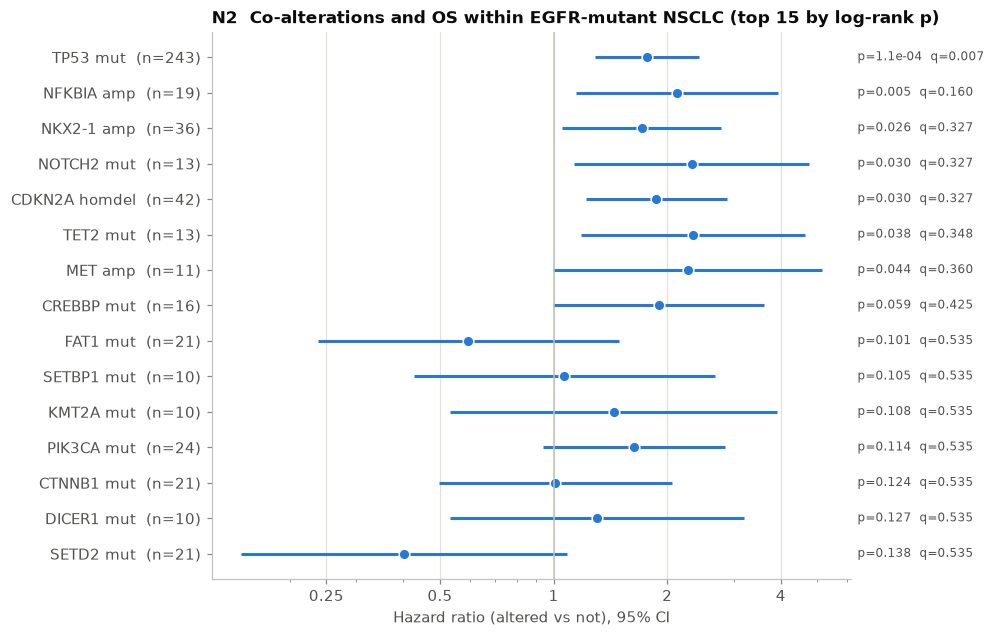

In [7]:
scr2 = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel"), min_n=10, entry="entry", patients=egfr_ids)
scr2 = scr2[scr2.gene != "EGFR"].reset_index(drop=True)
ax = cb.forest_plot(scr2, top=15, title="N2  Co-alterations and OS within EGFR-mutant NSCLC (top 15 by log-rank p)")
cb.save(DS, "N2", table=scr2, fig=ax.figure, slug="comutation_screen_in_egfr")
display(scr2.head(15))

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,TP53 mut absent,171,60,91.4,0.977,0.887,0.555,0.000114,NaN,NaN,NaN,NaN
1,TP53 mut present,243,130,44.9,0.917,0.762,0.399,0.000114,1.77,1.29,2.43,0.000398


[N2] signal: 1 of 64 co-alterations at FDR<0.1: TP53 mut (n=243) HR 1.77 q=0.0074


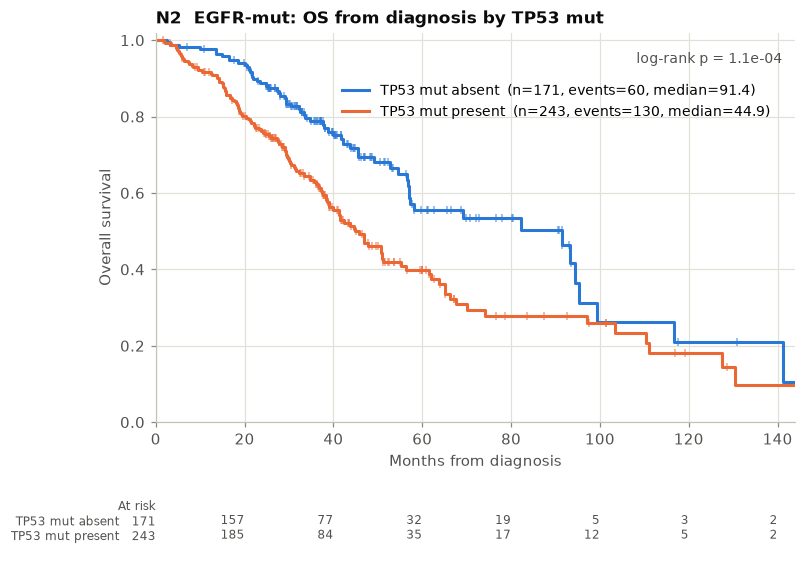

In [8]:
hits = scr2[scr2.q_bh < 0.1]
for g, k in ([("TP53", "mut")] + [(r.gene, r.kind) for r in hits.itertuples() if r.gene != "TP53"][:2]):
    d, t = cb.compare(S.loc[egfr_ids], A.status(g, k), labels=(f"{g} {k} absent", f"{g} {k} present"), entry="entry")
    ax, _ = cb.km_plot(d, "group", order=[f"{g} {k} absent", f"{g} {k} present"], title=f"N2  EGFR-mut: OS from diagnosis by {g} {k}", xlabel="Months from diagnosis")
    cb.save(DS, "N2", table=t, fig=ax.figure, slug=f"egfr_by_{g}_{k}")
    display(t)
cb.finding("N2", "signal" if len(hits) else "no signal",
           (f"{len(hits)} of {len(scr2)} co-alterations at FDR<0.1: " + "; ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()))
           if len(hits) else f"none of {len(scr2)} co-alterations passes FDR<0.1 (best {scr2.feature[0]} p={cb.fmt_p(scr2.p_logrank[0])})", F)

## N3 — Which alterations most commonly co-occur with EGFR, and do any convey a negative prognosis?
Frequency of each co-alteration in EGFR-mutant vs EGFR-wild-type patients (Fisher test), joined to the prognostic screen from N2.

,gene,kind,n_co_altered,pct_in_egfr_mut,pct_in_egfr_wt,p_fisher,median_os_with,median_os_without,HR_LT,p_logrank,q_bh_os
0,TP53,mut,243,58.7,52.3,0.0219,44.9,91.4,1.77,0.000114,0.00743
1,CDKN2A,homdel,42,10.9,6.9,0.0168,34.7,56.9,1.87,0.0302,0.327
2,CDKN2B,homdel,41,10.6,6.3,0.00687,37.1,56.7,1.61,0.22,0.604
3,NKX2-1,amp,36,9.3,3.9,0.000109,54.5,56.7,1.71,0.0256,0.327
4,KMT2D,mut,29,7.5,11.4,0.0287,130,56.5,0.725,0.346,0.81
5,RB1,mut,27,6.7,4.4,0.0872,42.3,57,1.43,0.293,0.761
6,RBM10,mut,27,8.7,10.7,0.384,65.1,56.5,1.03,0.911,0.987
7,MDM2,amp,26,6.7,4.7,0.115,63.8,56.4,0.923,0.723,0.93
8,APC,mut,26,6.4,5.4,0.458,56.4,56.7,1.04,0.729,0.93
9,SMARCA4,mut,26,6.7,9.3,0.122,41.8,56.7,1.57,0.211,0.604


[N3] signal: Top co-alterations in EGFR-mut: TP53 mut 58.7%, CDKN2A homdel 10.9%, CDKN2B homdel 10.6%, NKX2-1 amp 9.3%, KMT2D mut 7.5%; negative prognosis at FDR<0.1: TP53 mut HR 1.77


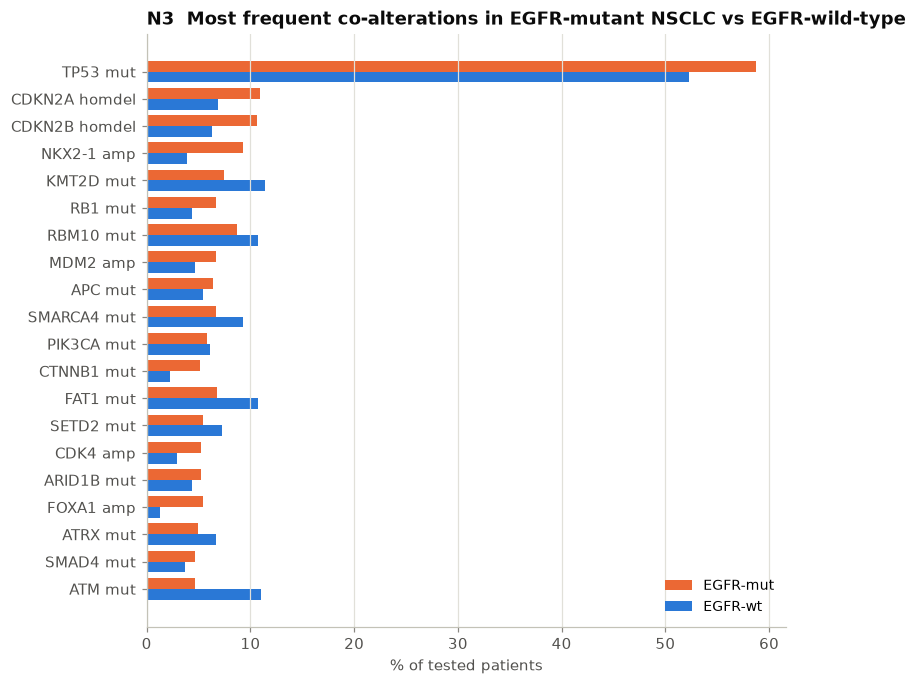

In [9]:
co = A.cooccurrence(egfr, kinds=("mut", "amp", "homdel"), min_n=10)
co = co[co.gene != "EGFR"].sort_values("altered_in_anchor", ascending=False)
top = co.head(20)
fig, ax = plt.subplots(figsize=(7.5, 7))
y = np.arange(len(top))[::-1]
ax.barh(y + 0.2, top.pct_in_anchor, height=0.4, color=cb.PALETTE[1], label="EGFR-mut")
ax.barh(y - 0.2, top.pct_in_rest, height=0.4, color=cb.PALETTE[0], label="EGFR-wt")
ax.set_yticks(y); ax.set_yticklabels(top.gene + " " + top.kind); ax.set_xlabel("% of tested patients"); ax.legend()
ax.set_title("N3  Most frequent co-alterations in EGFR-mutant NSCLC vs EGFR-wild-type", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
prog = scr2[["gene", "kind", "median_alt", "median_wt", "HR", "HR_lo", "HR_hi", "p_logrank", "q_bh"]].rename(
    columns={"median_alt": "median_os_with", "median_wt": "median_os_without", "HR": "HR_LT", "q_bh": "q_bh_os"})
n3 = top.rename(columns={"q_bh": "q_fisher", "n_anchor": "n_egfr_mut", "altered_in_anchor": "n_co_altered",
                         "pct_in_anchor": "pct_in_egfr_mut", "pct_in_rest": "pct_in_egfr_wt"}).merge(prog, on=["gene", "kind"], how="left")
cb.save(DS, "N3", table=n3, fig=fig, slug="cooccurrence_with_prognosis")
display(n3[["gene", "kind", "n_co_altered", "pct_in_egfr_mut", "pct_in_egfr_wt", "p_fisher", "median_os_with", "median_os_without", "HR_LT", "p_logrank", "q_bh_os"]])
bad = n3[(n3.q_bh_os < 0.1) & (n3.HR_LT > 1)]
cb.finding("N3", "signal" if len(bad) else "descriptive",
           "Top co-alterations in EGFR-mut: " + ", ".join(f"{r.gene} {r.kind} {r.pct_in_egfr_mut}%" for r in n3.head(5).itertuples()) +
           ("; negative prognosis at FDR<0.1: " + ", ".join(f"{r.gene} {r.kind} HR {r.HR_LT:.2f}" for r in bad.itertuples()) if len(bad) else "; none of the frequent co-alterations is prognostic at FDR<0.1"), F)

## N4 (replicate) — In EGFR+ patients osimertinib clearly outperforms chemotherapy
cBioPortal figure on slide 5, EGFR-mutant patients on osimertinib vs on chemotherapy. cBioPortal's "OS from start of treatment"
attributes are defined **per regimen** (e.g. `Osimertinib`, `Carboplatin, Pemetrexed Disodium`), and its group comparison drops
patients who fall in both groups. Three views are shown:

1. **OS from diagnosis**, patients grouped by the treatment they ever received (non-overlapping). This is the view that makes osimertinib look "clearly better", and it is immortal-time bias: osimertinib was mostly 2nd+ line here (T790M era), so its patients had already survived first-line therapy.
2. **OS from regimen start**, metastatic setting, any line: osimertinib monotherapy regimen vs first chemotherapy regimen without an EGFR TKI.
3. First-line regimens only.

Plus OS from regimen start for each individual chemotherapy regimen (the way cBioPortal exposes it).

EGFR-mut, metastatic setting: osimertinib monotherapy 129; chemotherapy without EGFR TKI 137; received both 57


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,received osimertinib (never chemo),72,31,67.5,0.972,0.884,0.574,0.000639
1,received both,57,41,41.2,1,0.789,0.157,0.000639
2,received chemotherapy (never osimertinib),80,53,37.7,0.925,0.741,0.271,0.000639


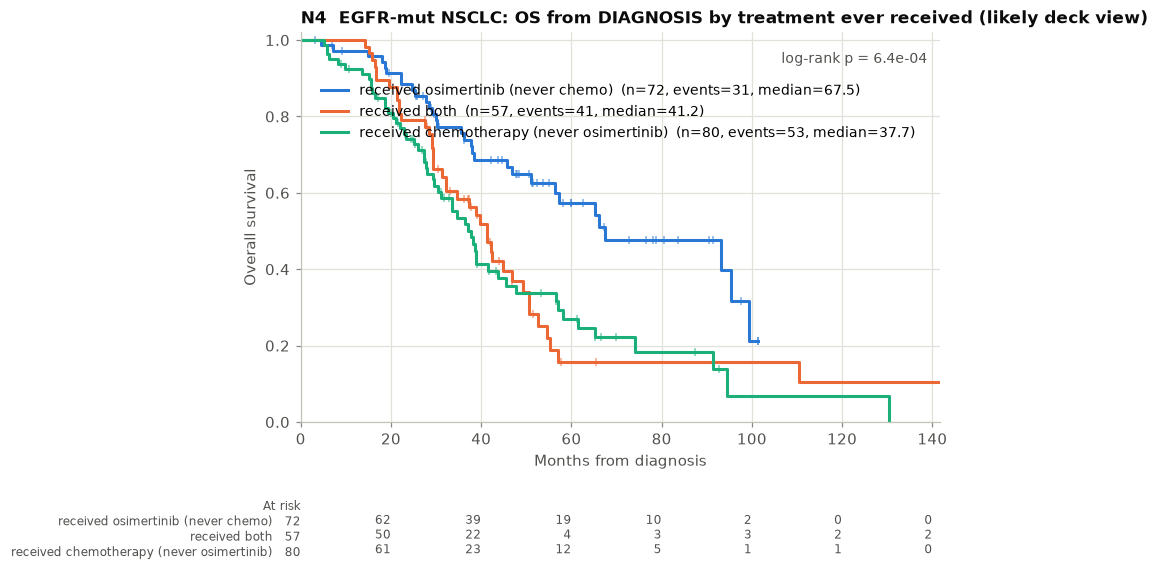

In [10]:
osi = b.survival_regimen(exact="Osimertinib")                      # the regimen cBioPortal calls "Osimertinib"
osi = osi[osi.index.isin(egfr_ids) & osi.met_setting]
chemo = b.survival_regimen(pattern="|".join(cb.CHEMO), exclude="|".join(cb.EGFR_TKI))
chemo = chemo[chemo.index.isin(egfr_ids) & chemo.met_setting]
both = osi.index.intersection(chemo.index)
print(f"EGFR-mut, metastatic setting: osimertinib monotherapy {len(osi)}; chemotherapy without EGFR TKI {len(chemo)}; received both {len(both)}")
# view 1: OS from diagnosis by treatment ever received (non-overlapping groups, as in cBioPortal's group comparison)
d40 = pd.concat([S.loc[osi.index.difference(both)].assign(group="received osimertinib (never chemo)"),
                 S.loc[chemo.index.difference(both)].assign(group="received chemotherapy (never osimertinib)"),
                 S.loc[both].assign(group="received both")])
ax, tab0 = cb.km_plot(d40, "group", order=["received osimertinib (never chemo)", "received both", "received chemotherapy (never osimertinib)"],
                      title="N4  EGFR-mut NSCLC: OS from DIAGNOSIS by treatment ever received (likely deck view)", xlabel="Months from diagnosis")
cb.save(DS, "N4", table=tab0, fig=ax.figure, slug="os_from_dx_by_treatment_received")
display(tab0)

line of therapy,1,2,3,4+,All
group,,,,,
"Chemotherapy, no EGFR TKI",68,27,28,14,137
Osimertinib,11,50,32,36,129
All,79,77,60,50,266


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_osi_vs_chemo,HR_lo,HR_hi,p_cox
0,Osimertinib,129,72,20.8,0.677,0.456,0.235,0.205,0.925,0.667,1.28,0.638
1,"Chemotherapy, no EGFR TKI",137,94,25.5,0.772,0.524,0.169,0.205,0.925,0.667,1.28,0.638


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_osi_vs_chemo
0,Osimertinib,11,4,26.9,0.857,0.714,0,0.657,0.871
1,"Chemotherapy, no EGFR TKI",68,45,34.1,0.912,0.668,0.263,0.657,0.871


,regimen,n,events,median_months,surv_1y,surv_2y,surv_5y,first_line_pct
0,"Cisplatin, Pemetrexed Disodium",19,10,55,0.947,0.789,0.356,63.2
1,Erlotinib Hydrochloride,159,105,37,0.88,0.654,0.259,58.5
2,"Investigational Drug, Investigational Drug",38,22,28.9,0.678,0.528,0.119,47.4
3,"Carboplatin, Paclitaxel",10,6,27,1,0.714,0,40
4,Afatinib Dimaleate,36,27,25.4,0.718,0.517,0.094,30.6
5,Investigational Drug,54,37,22.5,0.693,0.444,0.145,31.5
6,"Bevacizumab, Carboplatin, Pemetrexed Disodium",32,18,21.4,0.822,0.496,0.283,25
7,Osimertinib,129,72,20.8,0.677,0.456,0.235,8.5
8,"Carboplatin, Pemetrexed Disodium",58,44,16.7,0.661,0.361,0.036,31
9,Pembrolizumab,30,20,14.5,0.524,0.338,0.254,40


[N4] not supported as a treatment effect: From diagnosis (deck view): received-osimertinib median 67.5 vs received-chemo 37.7 mo, p=6.4e-04 (immortal time: osimertinib is 2nd+ line in 91% of patients). From regimen start, metastatic setting: osimertinib n=129 median 20.8 vs chemo n=137 median 25.5 mo, p=0.205, HR (LT) 0.92. First line only: n=11 vs 68, median 26.9 vs 34.1 mo, p=0.657.


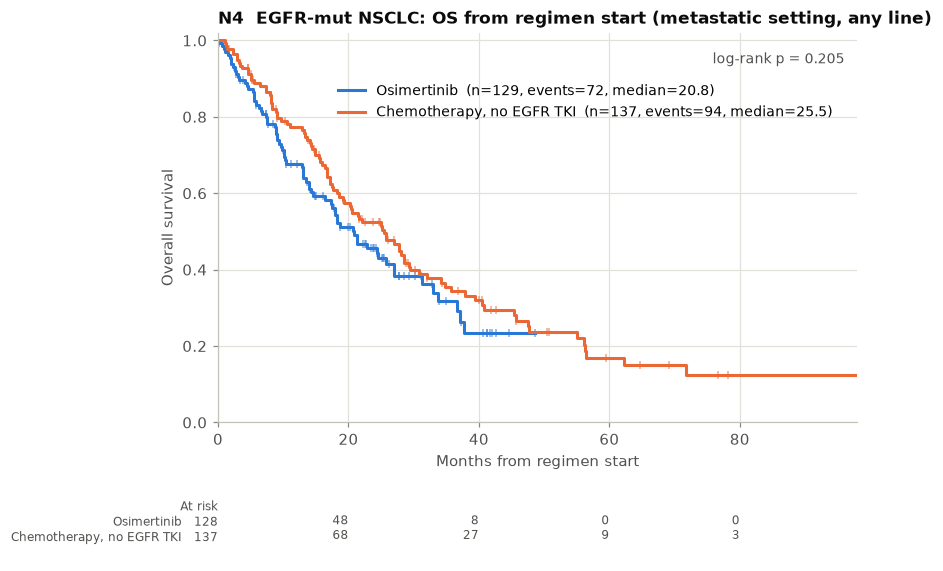

In [11]:
# view 2: OS from regimen start, metastatic setting, any line
d4 = pd.concat([osi.assign(group="Osimertinib"), chemo.assign(group="Chemotherapy, no EGFR TKI")]).reset_index()
display(pd.crosstab(d4.group, d4.line.clip(upper=4).astype(int).astype(str).replace("4", "4+"), margins=True).rename_axis(columns="line of therapy"))
ax, tab = cb.km_plot(d4, "group", order=["Osimertinib", "Chemotherapy, no EGFR TKI"], title="N4  EGFR-mut NSCLC: OS from regimen start (metastatic setting, any line)", xlabel="Months from regimen start")
h = cb.hr(d4.assign(feat=(d4.group == "Osimertinib")), "feat", entry="entry")
tab["HR_LT_osi_vs_chemo"] = h["HR"]; tab["HR_lo"] = h["HR_lo"]; tab["HR_hi"] = h["HR_hi"]; tab["p_cox"] = h["p_cox"]
cb.save(DS, "N4", table=tab, fig=ax.figure, slug="osimertinib_vs_chemo_from_regimen_start")
display(tab)
# view 3: first-line only
d41 = d4[d4.line == 1]
tab1 = cb.km_table(d41, "group", order=["Osimertinib", "Chemotherapy, no EGFR TKI"])
h1 = cb.hr(d41.assign(feat=(d41.group == "Osimertinib")), "feat", entry="entry")
tab1["HR_LT_osi_vs_chemo"] = h1["HR"]
cb.save(DS, "N4", table=tab1, slug="osimertinib_vs_chemo_firstline")
display(tab1)
# per-regimen view (cBioPortal style): OS from start of each common regimen among EGFR-mut patients
rows = []
for reg in b.regimens[b.regimens.record_id.isin(egfr_ids)].regimen_drugs.value_counts().head(12).index:
    R = b.survival_regimen(exact=reg); R = R[R.index.isin(egfr_ids) & R.met_setting]
    if len(R) >= 10:
        rows.append(cb.km_table(R.assign(g=reg), "g").assign(first_line_pct=round(100 * (R.line == 1).mean(), 1)))
per_reg = pd.concat(rows).drop(columns="p_logrank").rename(columns={"group": "regimen"}).sort_values("median_months", ascending=False).reset_index(drop=True)
cb.save(DS, "N4", table=per_reg, slug="per_regimen_os_egfr_mut")
display(per_reg)
cb.finding("N4", "not supported as a treatment effect",
           f"From diagnosis (deck view): received-osimertinib median {tab0.median_months[0]} vs received-chemo {tab0.median_months[2]} mo, p={cb.fmt_p(tab0.p_logrank[0])} (immortal time: osimertinib is 2nd+ line in {100 - round(100 * (osi.line == 1).mean())}% of patients). "
           f"From regimen start, metastatic setting: osimertinib n={tab.n[0]} median {tab.median_months[0]} vs chemo n={tab.n[1]} median {tab.median_months[1]} mo, p={cb.fmt_p(tab.p_logrank[0])}, HR (LT) {h['HR']:.2f}. "
           f"First line only: n={tab1.n[0]} vs {tab1.n[1]}, median {tab1.median_months[0]} vs {tab1.median_months[1]} mo, p={cb.fmt_p(tab1.p_logrank[0])}.", F)

## N5 — Mutation profiles of EGFR+ patients who respond well vs poorly to osimertinib
Response is not curated directly. BPC progression-free survival counts any imaging or oncologist note of progression, so its median on
osimertinib here is only ~5 months (far below trial PFS) and a PFS cut would label most patients "poor".
**Default definition used (open question for Jacob):** time to next treatment for this cancer (`ttnt_ca_seq`; event = next regimen or death).
*Good* = no next regimen or death for ≥ 12 months; *poor* = next regimen or death within 6 months; patients in between, or censored before 12 months, are excluded.
All osimertinib-containing regimens count. The alteration profile comes from the patient's earliest sequenced sample, which may pre- or post-date osimertinib.

response
good (>= 12 mo without next treatment)    60
poor (next treatment or death < 6 mo)     48
indeterminate                             40
Name: EGFR-mut patients on osimertinib, dtype: int64

,gene,kind,n_good,altered_good,pct_good,n_poor,altered_poor,pct_poor,p_fisher,q_bh
2,CTNNB1,mut,60,10,16.7,48,1,2.1,0.0213,0.671
58,DNMT3A,mut,57,0,0,42,4,9.5,0.0297,0.671
32,MYC,amp,57,2,3.5,42,7,16.7,0.0342,0.671
57,CREBBP,mut,57,0,0,42,3,7.1,0.0732,0.671
55,CDKN2A,mut,59,0,0,45,3,6.7,0.0779,0.671
56,CIC,mut,45,0,0,35,3,8.6,0.0797,0.671
41,MGA,mut,44,2,4.5,31,5,16.1,0.118,0.87
11,EPHA5,mut,50,4,8,37,0,0,0.133,0.873
9,FAT1,mut,45,5,11.1,35,1,2.9,0.223,1
13,GRIN2A,amp,38,3,7.9,30,0,0,0.249,1


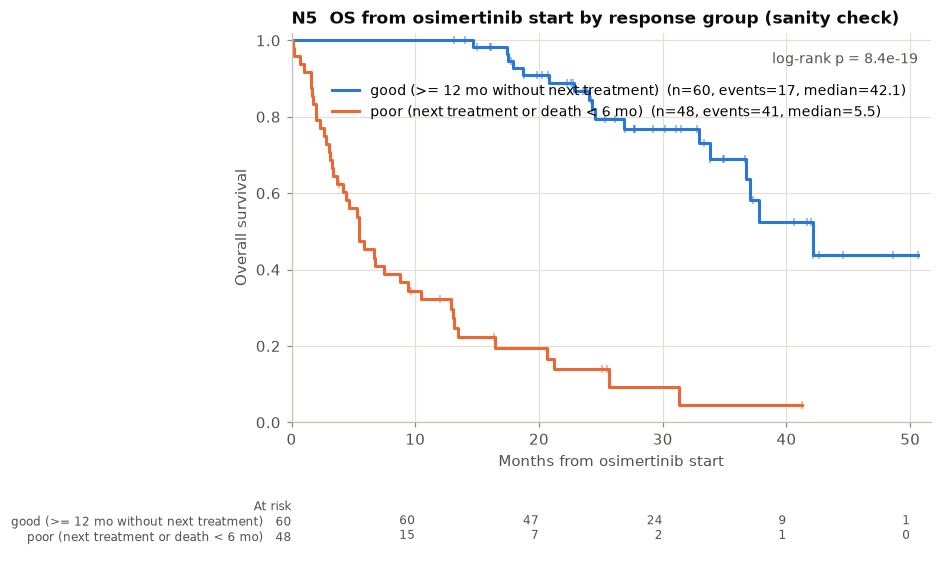

In [12]:
osi_all = b.survival_regimen(pattern="Osimertinib"); osi_all = osi_all[osi_all.index.isin(egfr_ids)]
good_lab, poor_lab = "good (>= 12 mo without next treatment)", "poor (next treatment or death < 6 mo)"
o = osi_all.dropna(subset=["ttnt_time", "ttnt_event"]).copy()
o["response"] = np.select([(o.ttnt_event == 1) & (o.ttnt_time < 6), o.ttnt_time >= 12], [poor_lab, good_lab], default="indeterminate")
display(o.response.value_counts().rename("EGFR-mut patients on osimertinib"))
gp = o[o.response != "indeterminate"]
ax, tab5 = cb.km_plot(gp.reset_index(), "response", order=[good_lab, poor_lab], title="N5  OS from osimertinib start by response group (sanity check)", xlabel="Months from osimertinib start")
anchor = gp.response.eq(good_lab)
prof5 = A.cooccurrence(anchor, kinds=("mut", "amp", "homdel"), min_n=3)
prof5 = prof5[prof5.gene != "EGFR"].rename(columns={"n_anchor": "n_good", "altered_in_anchor": "altered_good", "pct_in_anchor": "pct_good",
                                                    "n_rest": "n_poor", "altered_in_rest": "altered_poor", "pct_in_rest": "pct_poor"}).sort_values("p_fisher")
cb.save(DS, "N5", table=prof5, fig=ax.figure, slug="good_vs_poor_responder_profiles")
display(prof5.head(15))

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,NKX2-1 amp,NKX2-1,amp,18,120,17,85,8.8,12.2,0.0102,1.88,1.08,3.26,0.0254,132,0.164
1,CTNNB1 mut,CTNNB1,mut,13,135,9,102,26,9,0.0626,0.663,0.332,1.32,0.243,142,0.355
2,MYC amp,MYC,amp,10,128,7,95,2.4,12.2,0.0758,1.94,0.893,4.21,0.0941,132,0.355
3,MDM2 amp,MDM2,amp,14,124,12,90,9.7,10.6,0.0925,1.55,0.82,2.92,0.177,132,0.355
4,FOXA1 amp,FOXA1,amp,11,121,10,86,13.8,10.6,0.227,1.37,0.682,2.76,0.376,126,0.406
5,TERT amp,TERT,amp,8,124,7,89,7.7,12.4,0.229,1.56,0.719,3.39,0.26,126,0.406
6,RB1 mut,RB1,mut,10,134,10,97,8.5,11,0.235,1.51,0.786,2.92,0.215,138,0.406
7,NFKBIA amp,NFKBIA,amp,10,128,9,93,13.8,10.3,0.242,1.49,0.741,2.99,0.264,132,0.406
8,MGA mut,MGA,mut,10,97,7,66,4.5,12.4,0.253,1.5,0.643,3.48,0.35,102,0.406
9,ATRX mut,ATRX,mut,8,130,8,94,6.5,11,0.447,1.63,0.784,3.41,0.19,132,0.65


,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,MYC amp,MYC,amp,9,123,6,103,1.6,5.6,0.0205,2.91,1.25,6.8,0.0134,120,0.202
1,CTNNB1 mut,CTNNB1,mut,12,130,11,106,9.3,4.8,0.0374,0.47,0.215,1.03,0.0593,130,0.202
2,APC mut,APC,mut,8,130,5,109,7.1,5,0.165,0.45,0.165,1.23,0.12,126,0.514
3,RB1 mut,RB1,mut,10,128,8,106,4.4,5.5,0.182,1.5,0.69,3.28,0.304,126,0.514
4,TP53 mut,TP53,mut,92,50,77,40,4.7,7.1,0.193,1.25,0.835,1.88,0.276,130,0.514
5,NKX2-1 amp,NKX2-1,amp,17,115,16,93,5.1,5.5,0.244,1.45,0.841,2.51,0.18,120,0.557
6,MGA mut,MGA,mut,9,93,7,74,2.4,6.2,0.348,1.29,0.555,3,0.554,93,0.611
7,NFKBIA amp,NFKBIA,amp,10,122,10,99,4.6,5.5,0.395,1.41,0.728,2.73,0.309,120,0.611


[N5] no robust signal: good n=60, poor n=48. Profile differences at FDR<0.1: none. Time-to-next-treatment screen at FDR<0.1: none. PFS-I screen at FDR<0.1: none. Nominal top (TTNT): NKX2-1 amp HR 1.88 p=0.010.


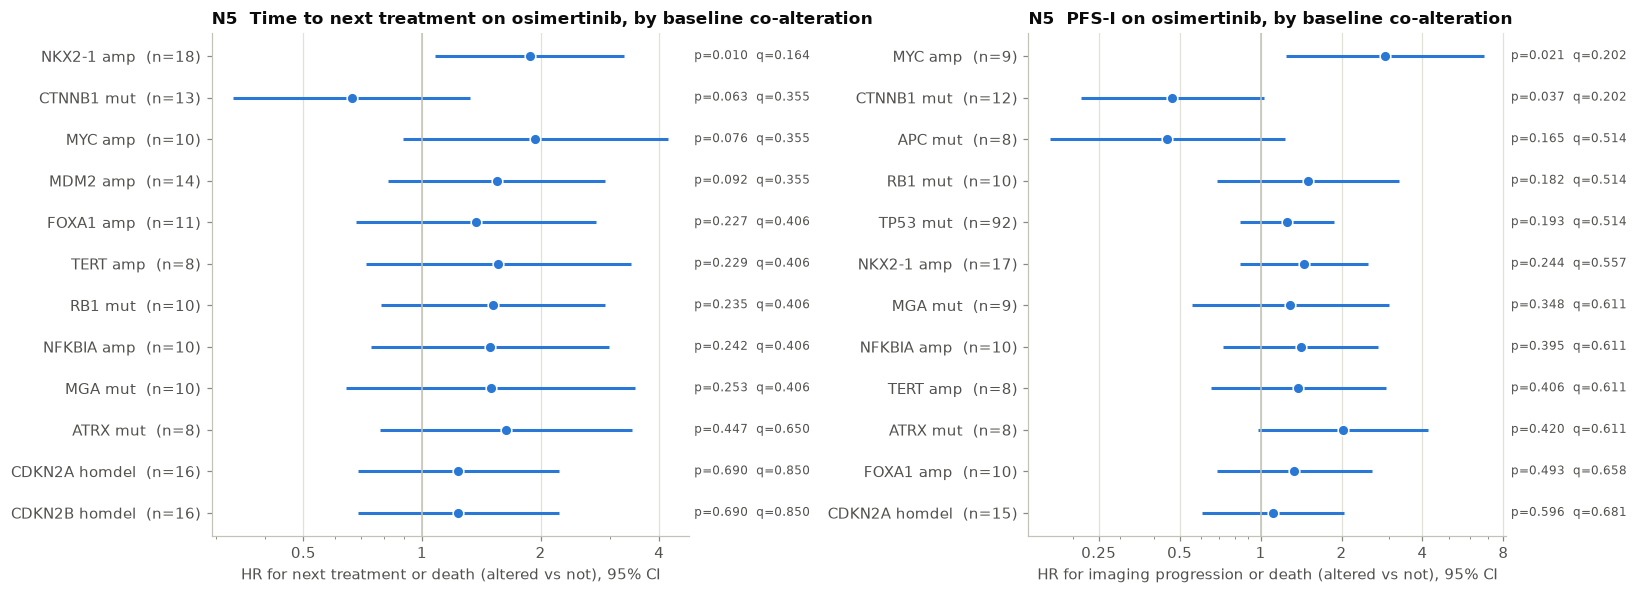

In [13]:
# Continuous version: which baseline co-alterations shorten time to next treatment, and PFS-I, on osimertinib (all EGFR-mut osimertinib-treated patients)
scr5 = cb.gene_screen(osi_all, A, kinds=("mut", "amp", "homdel"), min_n=8, time="ttnt_time", event="ttnt_event", entry="entry", patients=osi_all.index)
scr5 = scr5[scr5.gene != "EGFR"].reset_index(drop=True)
scr5p = cb.gene_screen(osi_all, A, kinds=("mut", "amp", "homdel"), min_n=8, time="pfs_i_time", event="pfs_i_event", entry="entry", patients=osi_all.index)
scr5p = scr5p[scr5p.gene != "EGFR"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cb.forest_plot(scr5, top=12, title="N5  Time to next treatment on osimertinib, by baseline co-alteration", ax=axes[0])
axes[0].set_xlabel("HR for next treatment or death (altered vs not), 95% CI")
cb.forest_plot(scr5p, top=12, title="N5  PFS-I on osimertinib, by baseline co-alteration", ax=axes[1])
axes[1].set_xlabel("HR for imaging progression or death (altered vs not), 95% CI")
fig.tight_layout()
cb.save(DS, "N5", table=scr5, fig=fig, slug="ttnt_screen_on_osimertinib")
cb.save(DS, "N5", table=scr5p, slug="pfs_i_screen_on_osimertinib")
display(scr5.head(12)); display(scr5p.head(8))
sig5 = prof5[prof5.q_bh < 0.1]; sig5b = scr5[scr5.q_bh < 0.1]; sig5c = scr5p[scr5p.q_bh < 0.1]
cb.finding("N5", "signal" if (len(sig5) or len(sig5b) or len(sig5c)) else "no robust signal",
           f"good n={int(anchor.sum())}, poor n={int((~anchor).sum())}. Profile differences at FDR<0.1: " +
           (", ".join(f"{r.gene} {r.kind} {r.pct_good}% vs {r.pct_poor}%" for r in sig5.itertuples()) or "none") +
           ". Time-to-next-treatment screen at FDR<0.1: " + (", ".join(f"{r.feature} HR {r.HR:.2f}" for r in sig5b.itertuples()) or "none") +
           ". PFS-I screen at FDR<0.1: " + (", ".join(f"{r.feature} HR {r.HR:.2f}" for r in sig5c.itertuples()) or "none") +
           f". Nominal top (TTNT): {scr5.feature[0]} HR {scr5.HR[0]:.2f} p={cb.fmt_p(scr5.p_logrank[0])}.", F)

## N6 — EGFR vs KEAP1 vs STK11 vs KEAP1+STK11: OS and response to different treatments
Mutually exclusive profiles over the three genes, restricted to patients tested for all three (slides 6–8). cBioPortal dropped the KEAP1+STK11 overlap; here it is its own group. Patients with other combinations (e.g. EGFR+KEAP1) are listed but not plotted.

profile
none of the three    909
EGFR                 366
STK11                127
KEAP1+STK11          109
KEAP1                 98
other combination     18
Name: patients, dtype: int64

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,none of the three,909,424,51.6,0.857,0.714,0.419,1.01e-07
1,EGFR,366,155,56.5,0.945,0.817,0.47,1.01e-07
2,KEAP1,98,57,31.9,0.78,0.613,0.385,1.01e-07
3,STK11,127,69,41.3,0.83,0.682,0.382,1.01e-07
4,KEAP1+STK11,109,72,29.5,0.652,0.555,0.28,1.01e-07


,HR,HR_lo,HR_hi,p,model
covariate,,,,,
profile_EGFR,0.842,0.696,1.02,0.0789,left-truncated
profile_KEAP1,1.57,1.18,2.08,0.00207,left-truncated
profile_STK11,1.23,0.942,1.61,0.128,left-truncated
profile_KEAP1+STK11,1.74,1.33,2.28,6.3e-05,left-truncated
profile_EGFR,0.739,0.609,0.896,0.00209,left-truncated + stage + age
profile_KEAP1,1.4,1.05,1.87,0.0203,left-truncated + stage + age
profile_STK11,1.31,1,1.71,0.0502,left-truncated + stage + age
profile_KEAP1+STK11,2.02,1.54,2.65,4.23e-07,left-truncated + stage + age


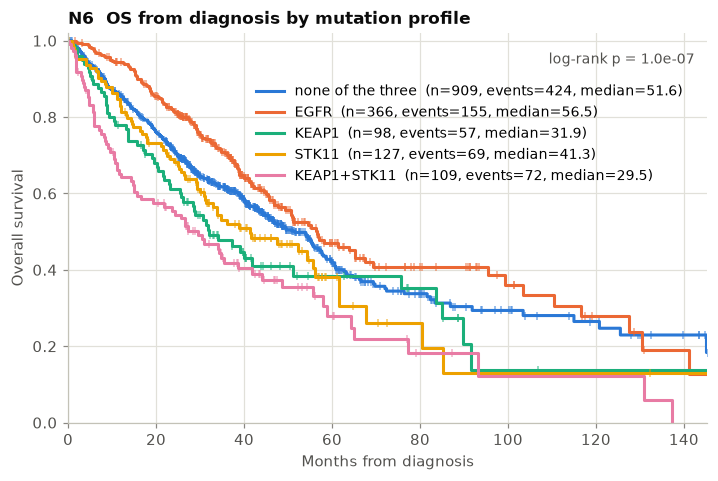

In [14]:
prof6 = A.combo_groups(["EGFR", "KEAP1", "STK11"], min_n=10, wt_label="none of the three")
order6 = ["none of the three", "EGFR", "KEAP1", "STK11", "KEAP1+STK11"]
display(prof6.value_counts().rename("patients"))
d6 = S.join(prof6, how="inner")
d6 = d6[d6.profile.isin(order6)]
ax, tab6 = cb.km_plot(d6, "profile", order=order6, title="N6  OS from diagnosis by mutation profile", xlabel="Months from diagnosis")
d6c = d6.assign(profile=pd.Categorical(d6.profile, order6))
_, cox6 = cb.cox_fit(d6c, ["profile"], entry="entry")
_, cox6a = cb.cox_fit(d6c, ["profile", "stage_dx", "age_dx"], entry="entry")
cox6["model"] = "left-truncated"; cox6a["model"] = "left-truncated + stage + age"
cb.save(DS, "N6", table=tab6, fig=ax.figure, slug="profiles_os")
cb.save(DS, "N6", table=pd.concat([cox6, cox6a]), slug="profiles_cox")
display(tab6)
display(pd.concat([cox6, cox6a]).loc[lambda t: t.index.str.startswith("profile")])

n                                                              median_months                                                             
treatment         EGFR TKI immunotherapy-containing platinum chemotherapy, no IO or TKI      EGFR TKI immunotherapy-containing platinum chemotherapy, no IO or TKI
group                                                                                                                                                             
none of the three       28                      264                                 507          14.3                     12.9                                35.7
EGFR                   207                       68                                 152          37.6                     12.1                                40.5
KEAP1                    1                       39                                  64           1.6                     14.9                                30.8
STK11                    5                       42                                  69          22.8                       12                                29.6
KEAP1+STK11              1                       35                                  61          39.7                        6                                13.7

[N6] signal: OS from dx: median none=51.6, EGFR=56.5, KEAP1=31.9, STK11=41.3, KEAP1+STK11=29.5 mo; log-rank p=1.0e-07. Adjusted HR vs none: EGFR 0.74, KEAP1 1.40, STK11 1.31, KEAP1+STK11 2.02. On immunotherapy: median none=12.9, KEAP1=14.9, STK11=12.0, KEAP1+STK11=6.0 mo (p=0.248).


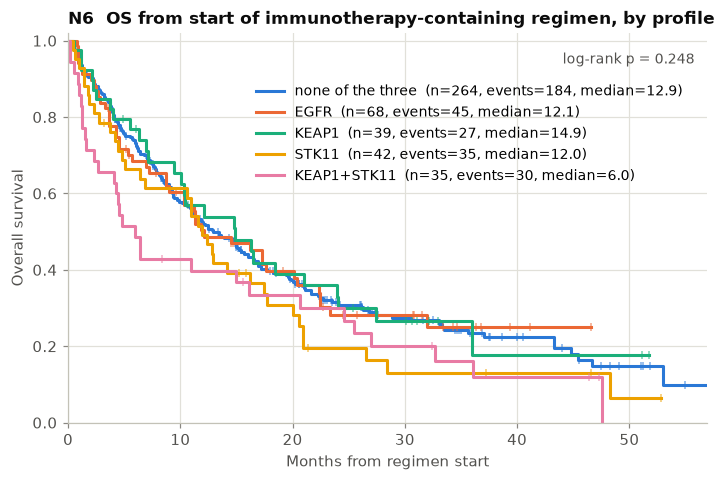

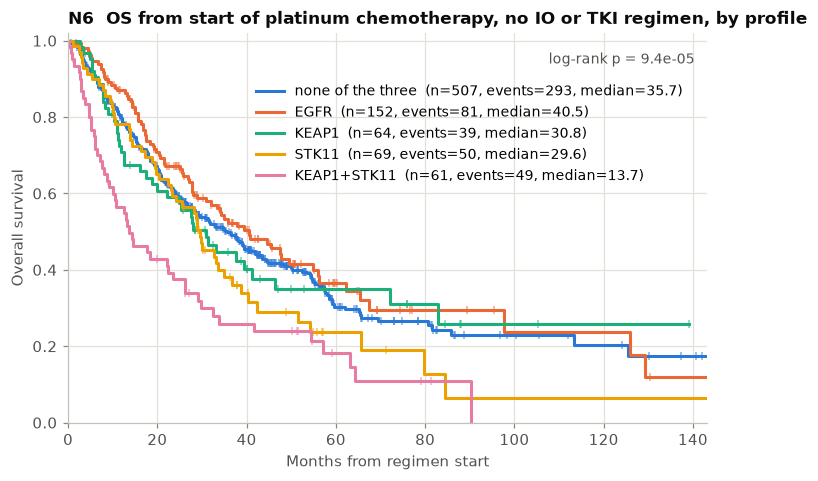

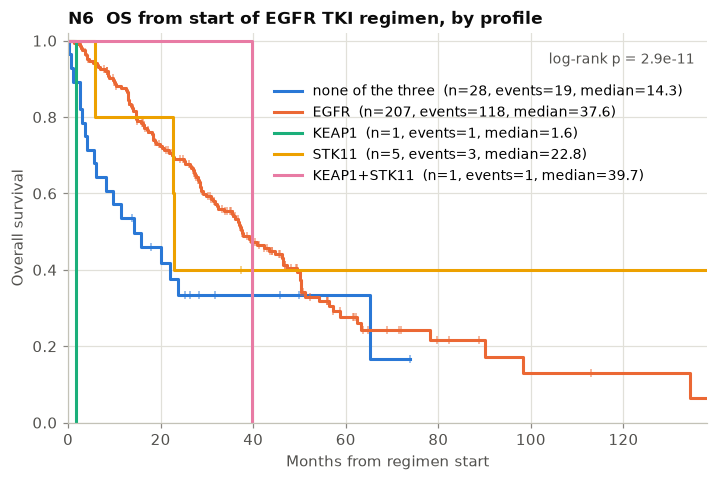

In [15]:
classes = {
    "immunotherapy-containing": dict(pattern="|".join(cb.IO)),
    "platinum chemotherapy, no IO or TKI": dict(pattern="Carboplatin|Cisplatin", exclude="|".join(cb.IO + cb.EGFR_TKI)),
    "EGFR TKI": dict(pattern="|".join(cb.EGFR_TKI)),
}
rows = []
for name, kw in classes.items():
    R = b.survival_regimen(**kw).join(prof6, how="inner")
    R = R[R.profile.isin(order6)]
    ax, t = cb.km_plot(R, "profile", order=order6, title=f"N6  OS from start of {name} regimen, by profile", xlabel="Months from regimen start")
    t["treatment"] = name
    rows.append(t)
    cb.save(DS, "N6", table=t, fig=ax.figure, slug="by_" + re.sub(r"[^a-z]+", "_", name))
t6 = pd.concat(rows)
piv = t6.pivot(index="group", columns="treatment", values=["n", "median_months"]).reindex(order6)
display(piv)
io = t6[t6.treatment == "immunotherapy-containing"].set_index("group")
cb.finding("N6", "signal",
           f"OS from dx: median none={tab6.median_months[0]}, EGFR={tab6.median_months[1]}, KEAP1={tab6.median_months[2]}, STK11={tab6.median_months[3]}, KEAP1+STK11={tab6.median_months[4]} mo; "
           f"log-rank p={cb.fmt_p(tab6.p_logrank[0])}. Adjusted HR vs none: " +
           ", ".join(f"{i.replace('profile_', '')} {r.HR:.2f}" for i, r in cox6a.iterrows() if i.startswith("profile")) +
           f". On immunotherapy: median none={io.median_months.get('none of the three')}, KEAP1={io.median_months.get('KEAP1')}, STK11={io.median_months.get('STK11')}, "
           f"KEAP1+STK11={io.median_months.get('KEAP1+STK11')} mo (p={cb.fmt_p(io.p_logrank.iloc[0])}).", F)

## Summary of findings
One line per question. "signal" means something passed the pre-specified threshold; "descriptive" means the question asked for a ranking, not a test.

In [16]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,N1,confirmed,EGFR-mut (n=414) median OS 56.5 vs 42.3 mo in EGFR-wt; log-rank p=9.9e-06; HR (LT) 0.75 [0.64-0.89]. Stage IV only: HR 0.67. Classic sensitising mutations drive the benefit (median 63.8 mo).
1,N2,signal,1 of 64 co-alterations at FDR<0.1: TP53 mut (n=243) HR 1.77 q=0.0074
2,N3,signal,"Top co-alterations in EGFR-mut: TP53 mut 58.7%, CDKN2A homdel 10.9%, CDKN2B homdel 10.6%, NKX2-1 amp 9.3%, KMT2D mut 7.5%; negative prognosis at FDR<0.1: TP53 mut HR 1.77"
3,N4,not supported as a treatment effect,"From diagnosis (deck view): received-osimertinib median 67.5 vs received-chemo 37.7 mo, p=6.4e-04 (immortal time: osimertinib is 2nd+ line in 91% of patients). From regimen start, metastatic setting: osimertinib n=129 median 20.8 vs chemo n=137 median 25.5 mo, p=0.205, HR (LT) 0.92. First line only: n=11 vs 68, median 26.9 vs 34.1 mo, p=0.657."
4,N5,no robust signal,"good n=60, poor n=48. Profile differences at FDR<0.1: none. Time-to-next-treatment screen at FDR<0.1: none. PFS-I screen at FDR<0.1: none. Nominal top (TTNT): NKX2-1 amp HR 1.88 p=0.010."
5,N6,signal,"OS from dx: median none=51.6, EGFR=56.5, KEAP1=31.9, STK11=41.3, KEAP1+STK11=29.5 mo; log-rank p=1.0e-07. Adjusted HR vs none: EGFR 0.74, KEAP1 1.40, STK11 1.31, KEAP1+STK11 2.02. On immunotherapy: median none=12.9, KEAP1=14.9, STK11=12.0, KEAP1+STK11=6.0 mo (p=0.248)."
